# Coffee Leaf Disease Classification — End-to-End ML Pipeline

**Goal:** classify a photo of an Arabica coffee leaf into one of five classes so farmers can spot disease early:

| Class | What it is |
|---|---|
| **Cercospora** | Cercospora leaf spot (*Cercospora coffeicola*) |
| **Healthy** | No disease |
| **Leaf_rust** | Coffee leaf rust (*Hemileia vastatrix*), the most economically damaging coffee disease |
| **Miner** | Coffee leaf miner (*Leucoptera coffeella*) damage |
| **Phoma** | Phoma leaf spot / blight |

**Data (images, not tabular)** — Jepkoech et al., Mendeley Data, CC BY 4.0:
* JMuBEN — https://data.mendeley.com/datasets/t2r6rszp5c/1 (Cercospora, Leaf rust, Phoma)
* JMuBEN2 — https://data.mendeley.com/datasets/tgv3zb82nd/1 (Healthy, Miner)

**Notebook outline**
1. Data acquisition
2. Data audit — duplicate & leakage analysis
3. Exploratory data analysis and feature interpretation (feeds the UI dashboard)
4. Preprocessing
5. Model creation — baseline CNN vs. optimised MobileNetV2 transfer learning (hyper-parameter search, regularisation, early stopping, fine-tuning)
6. Model testing — accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix
7. Saving the model, exporting it for deployment, prediction function test
8. How retraining works

In [1]:
import os, sys, json, time, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from src.config import CLASS_NAMES, DATA_DIR, MODEL_PATH, BASELINE_MODEL_PATH, METRICS_PATH, SEED, IMG_SIZE
from src import preprocessing as P
from src import model as M

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Cercospora": "#8c6d31", "Healthy": "#2ca02c", "Leaf_rust": "#ff7f0e", "Miner": "#9467bd", "Phoma": "#d62728"}
print("TensorFlow", tf.__version__, "| project root:", ROOT)

I0000 00:00:1795121461.921616    2096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795121461.922193    2096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795121462.980158    2096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795121462.980476    2096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | project root: /home/claude/coffee_leaf_mlops


## 1. Data acquisition

Download both datasets from Mendeley (links above) and run:

```bash
python -m src.data_acquisition --sources t2r6rszp5c-1.zip jmuben2.zip
```

The script extracts the (nested) archives, maps folder names to labels, removes corrupted and duplicate files,
groups rotated/flipped copies, and performs a **group-aware train / validation / test split** (section 2 explains why).
The result is committed to the repo as `data/train/<class>/` and `data/test/<class>/`, with `data/split_manifest.csv`
recording each image's split (the validation images live inside `data/train` and are flagged `val` in the manifest).

The cell below re-runs acquisition only if the processed data is missing.

In [2]:
from src.data_acquisition import build
if not (DATA_DIR / "split_manifest.csv").exists():
    SOURCES = [Path("~/Downloads/t2r6rszp5c-1.zip").expanduser(), Path("~/Downloads/jmuben2_sample.zip").expanduser()]
    build(SOURCES)
summary = json.loads((DATA_DIR / "dataset_summary.json").read_text())
manifest = P.read_manifest()
import pandas as pd
df_sum = pd.DataFrame(summary).T[["raw", "unique", "groups", "train", "val", "test"]]
df_sum.loc["TOTAL"] = df_sum.sum()
df_sum

,raw,unique,groups,train,val,test
Cercospora,7681,322,81,209,45,68
Healthy,2885,60,12,40,10,10
Leaf_rust,8336,1042,521,678,156,208
Miner,2865,1321,460,857,198,266
Phoma,6571,691,181,447,108,136
TOTAL,28338,3436,1255,2231,517,688


## 2. Data audit — duplicates and leakage

The downloads contain **~28,300 files**, but most are copies:

* `raw` — files in the download
* `unique` — files left after removing **byte-identical** duplicates (MD5 hash)
* `groups` — distinct leaf photos after also merging **rotated / flipped** copies (perceptual hash that is the same for all 8 rotations/flips)

For example, the 2,885 *Healthy* files are only 60 unique files, and those come from just **12 distinct photos**.

**Why it matters:** with a random split, copies of the same leaf end up in both train and test, and the model scores
near-perfect by memorising them. We therefore:
1. drop exact duplicates, and
2. split **by group**, so every rotation/flip of a test leaf stays out of training.

The test scores below are therefore an honest estimate on leaves the model has never seen in any orientation.
Caveat: this project uses a random *sample* of JMuBEN2. We checked the full release: its ~19,000 Healthy files contain only 63 unique images, so the small number of distinct Healthy leaves (12) comes from the dataset itself, not our sampling. The Healthy test set (10 images from 2–3 leaves) is therefore small, and its per-class scores have high variance. New field photos added through the app's upload + retrain feature are how this gets fixed.

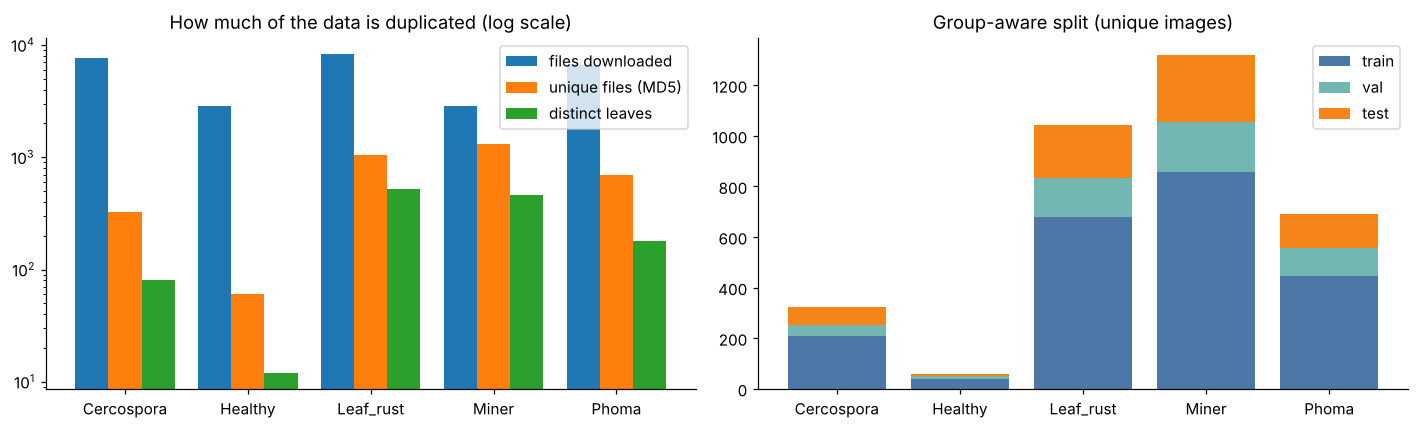

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(CLASS_NAMES)); w = 0.27
for i, (col, lab) in enumerate([("raw", "files downloaded"), ("unique", "unique files (MD5)"), ("groups", "distinct leaves")]):
    ax[0].bar(x + (i - 1) * w, [summary[c][col] for c in CLASS_NAMES], w, label=lab)
ax[0].set_xticks(x, CLASS_NAMES); ax[0].set_yscale("log"); ax[0].set_title("How much of the data is duplicated (log scale)"); ax[0].legend()
bottom = np.zeros(len(CLASS_NAMES))
for split, c in [("train", "#4c78a8"), ("val", "#72b7b2"), ("test", "#f58518")]:
    v = np.array([summary[k][split] for k in CLASS_NAMES]); ax[1].bar(CLASS_NAMES, v, bottom=bottom, label=split, color=c); bottom += v
ax[1].set_title("Group-aware split (unique images)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Takeaways:** after de-duplication the classes are imbalanced: Miner has ~22× more images than Healthy.
We correct for this with **class weights** in the loss and with strong **data augmentation**.

## 3. Exploratory data analysis
### 3.1 Sample images per class

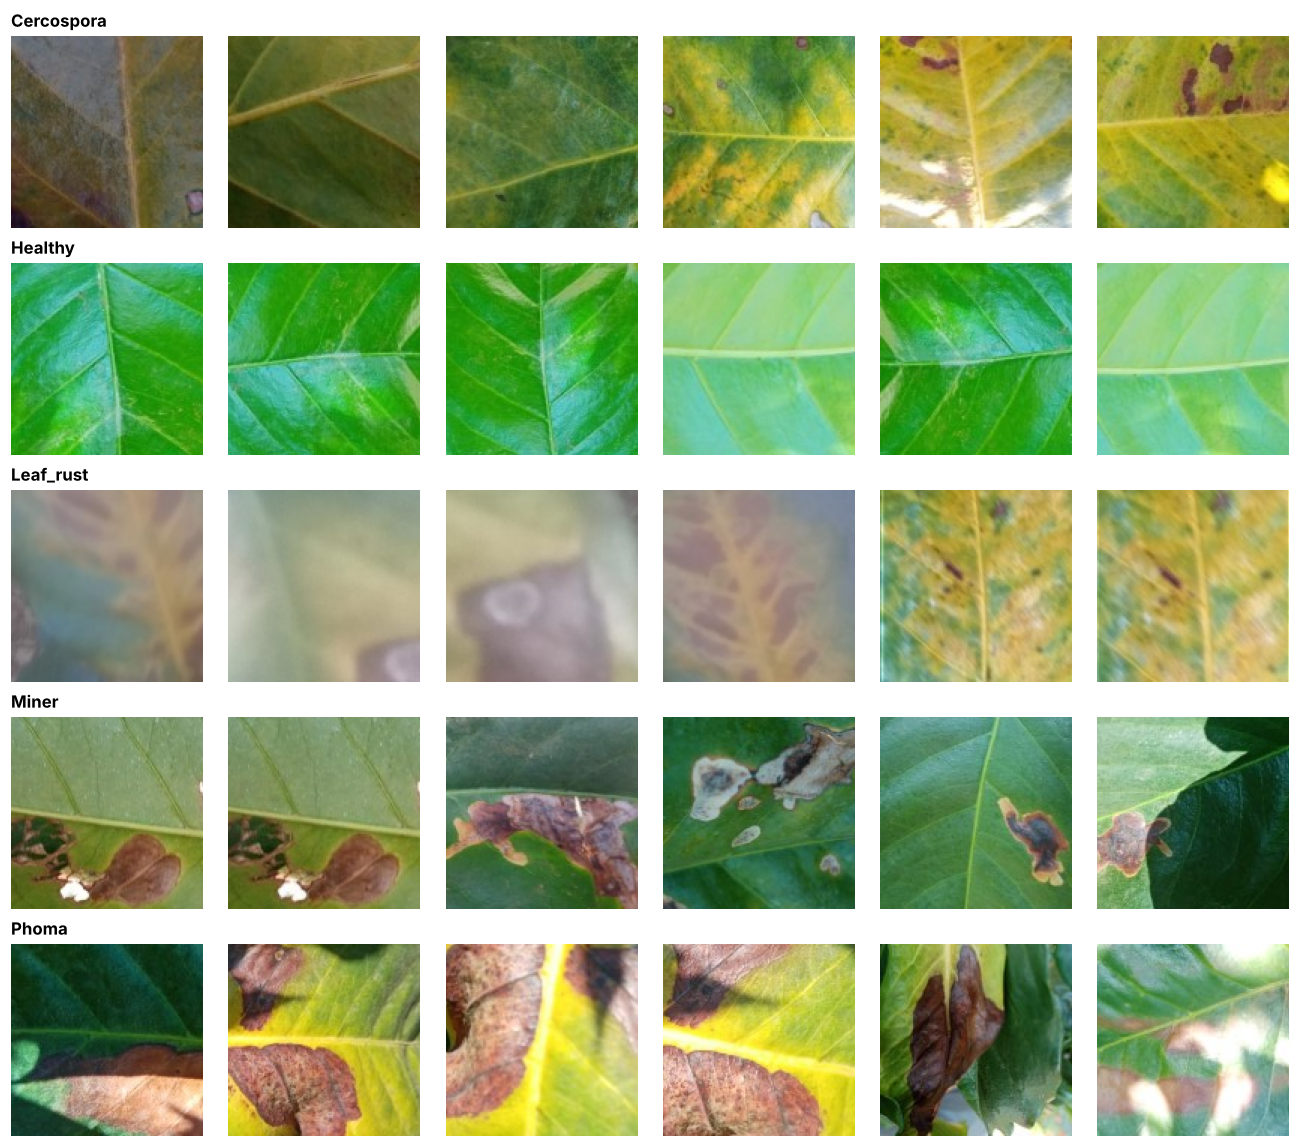

In [4]:
fig, axes = plt.subplots(len(CLASS_NAMES), 6, figsize=(12, 10.5))
for i, c in enumerate(CLASS_NAMES):
    files = sorted((DATA_DIR / "train" / c).glob("*"))
    for j, f in enumerate(random.Random(1).sample(files, 6)):
        axes[i, j].imshow(P.open_image(f)); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [5]:
from PIL import Image
sizes = pd.Series([Image.open(ROOT / r["path"]).size for r in manifest]).value_counts()
print("Image sizes (w, h):"); print(sizes.head())

Image sizes (w, h):
(128, 128)    3259
(122, 256)      10
(92, 256)        7
(111, 256)       7
(256, 120)       6
Name: count, dtype: int64


Almost all images are already **128 × 128 RGB**; a few Cercospora images are 83 × 128 and get resized.

### 3.2 Interpretable image features
To see what separates the classes, we compute features for every unique image (`src/preprocessing.image_features`):

* **green_index** — mean Excess-Green `(2G − R − B)/255`: how green the leaf is
* **lesion_fraction** — share of leaf pixels whose hue is *not* green (yellow / orange / brown / purple = spots, pustules, necrosis, mines)
* **texture** — mean gradient magnitude: spots, mines and pustules add edges
* **brightness** — mean HSV value
* **mean R / G / B** — colour profile

In [6]:
X_all, y_all, paths_all = [], [], []
for r in manifest:
    X_all.append(P.image_to_array(ROOT / r["path"])); y_all.append(CLASS_NAMES.index(r["label"]))
X_all, y_all = np.stack(X_all), np.array(y_all)
raw_counts = {c: summary[c]["raw"] for c in CLASS_NAMES}
insights = P.compute_insights(X_all, y_all, DATA_DIR / "insights.json", raw_counts=raw_counts)  # also used by the web UI
feats = pd.DataFrame([P.image_features(x) for x in X_all]); feats["label"] = [CLASS_NAMES[i] for i in y_all]
feats.groupby("label")[["green_index", "lesion_fraction", "texture", "brightness", "mean_r", "mean_g", "mean_b"]].agg(["mean", "std"]).round(3)

green_index        lesion_fraction        texture         \
                  mean    std            mean    std    mean    std   
label                                                                 
Cercospora       0.280  0.136           0.478  0.321   6.611  2.143   
Healthy          0.701  0.134           0.006  0.007   5.169  2.218   
Leaf_rust        0.060  0.069           0.749  0.304   2.808  1.397   
Miner            0.229  0.092           0.322  0.241   7.623  1.942   
Phoma            0.186  0.133           0.519  0.253   9.667  2.806   

           brightness          mean_r           mean_g           mean_b  \
                 mean    std     mean     std     mean     std     mean   
label                                                                     
Cercospora      0.553  0.157  124.242  43.033  136.134  41.769   76.686   
Healthy         0.727  0.084   94.831  37.700  185.499  21.347   97.287   
Leaf_rust       0.661  0.079  162.761  22.254  159.448  19.654  140.903   
Miner           0.540  0.102  109.181  30.890  132.740  26.346   97.819   
Phoma           0.614  0.140  136.646  40.817  143.432  34.699  102.878   

                    
               std  
label               
Cercospora  35.649  
Healthy     39.482  
Leaf_rust   21.543  
Miner       35.914  
Phoma       38.645

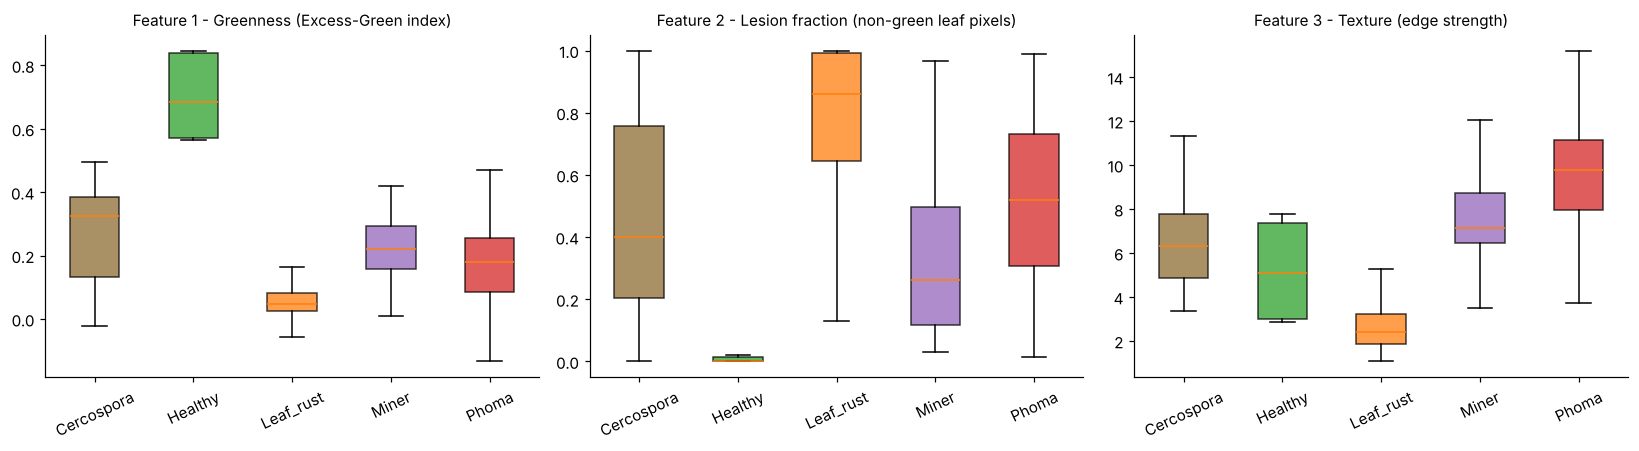

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, f, title in zip(axes, ["green_index", "lesion_fraction", "texture"],
                        ["Feature 1 - Greenness (Excess-Green index)", "Feature 2 - Lesion fraction (non-green leaf pixels)", "Feature 3 - Texture (edge strength)"]):
    data = [feats.loc[feats.label == c, f] for c in CLASS_NAMES]
    bp = ax.boxplot(data, tick_labels=CLASS_NAMES, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], CLASS_NAMES): patch.set_facecolor(COLORS[c]); patch.set_alpha(.75)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

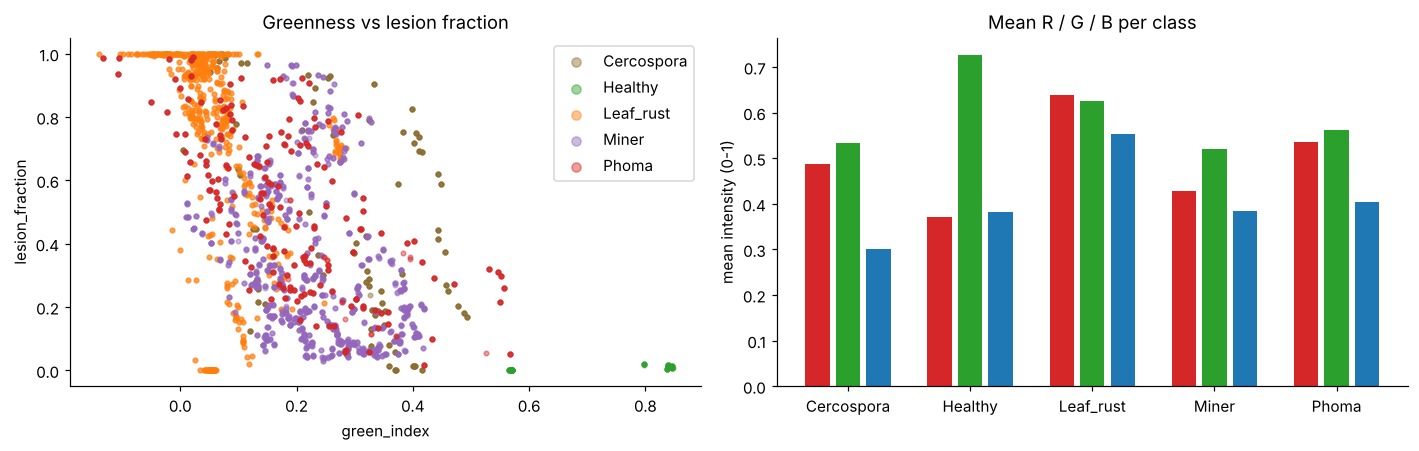

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for c in CLASS_NAMES:
    s = feats[feats.label == c]
    ax[0].scatter(s.green_index, s.lesion_fraction, s=9, alpha=.45, color=COLORS[c], label=c)
ax[0].set_xlabel("green_index"); ax[0].set_ylabel("lesion_fraction"); ax[0].legend(markerscale=2); ax[0].set_title("Greenness vs lesion fraction")
mc = np.array([insights["mean_color"][c] for c in CLASS_NAMES]) / 255
for i, c in enumerate(CLASS_NAMES):
    ax[1].bar(np.arange(3) + i * 4, mc[i], color=["#d62728", "#2ca02c", "#1f77b4"])
ax[1].set_xticks(np.arange(len(CLASS_NAMES)) * 4 + 1, CLASS_NAMES); ax[1].set_title("Mean R / G / B per class"); ax[1].set_ylabel("mean intensity (0-1)")
plt.tight_layout(); plt.show()

### 3.3 What story do the features tell?

1. **Greenness (green_index).** Healthy leaves are by far the greenest class: a healthy leaf has a strongly dominant
   green channel. Every disease lowers greenness because it replaces green chlorophyll tissue with yellow, orange or brown tissue.
   Leaf rust has the lowest greenness, consistent with its pale, washed-out, yellow-orange appearance.
2. **Lesion fraction.** Healthy leaves have almost no non-green leaf pixels, while Leaf rust, Cercospora and Phoma have the
   largest share of discoloured tissue. Miner damage forms distinct brown patches on an otherwise green leaf, so it sits in
   between. This feature is a crude "disease severity" score, and the classes ranked by it match agronomic intuition.
3. **Texture (edge strength).** Miner and Phoma images are the most textured (sharp lesion borders, leaf veins, background
   foliage). Leaf rust images are the smoothest: they are visibly blurred/out-of-focus close-ups. This is partly a
   **dataset artefact** (rust photos were captured differently), not only biology, so the model may partly rely on
   photo style for rust. That is a known risk to watch in production, and a reason for the retraining loop: field
   photos uploaded by users will break that shortcut.

No single feature separates all five classes. Overlaps such as Cercospora vs Phoma motivate a CNN that learns spatial
patterns (lesion shape, halo, location) rather than global colour statistics.

## 4. Preprocessing

| Step | Where | Why |
|---|---|---|
| Remove corrupted & duplicate files, group-aware split | `src/data_acquisition.py` | Prevent leakage / inflated metrics |
| Decode → RGB → (EXIF-orientation fix) → resize to 128×128 | `src/preprocessing.image_to_array` | Fixed input size; same function used by the API and retraining |
| Keep pixels as uint8 0–255 | — | Scaling lives **inside** the model, so training and serving cannot drift apart |
| Rescale to [-1, 1] | `Rescaling` layer in model | MobileNetV2's expected input range |
| Augmentation: flips, ±90° rotation, zoom, contrast | `augmentation_block` (train-time only) | Leaves have no canonical orientation; regularises a small dataset |
| Class weights | `P.class_weights` | Counter the 22:1 imbalance |

In [9]:
X_tr, y_tr, _ = P.load_split("train", manifest, ROOT)
X_val, y_val, _ = P.load_split("val", manifest, ROOT)
X_te, y_te, te_paths = P.load_split("test", manifest, ROOT)
print("train", X_tr.shape, "val", X_val.shape, "test", X_te.shape, "| dtype", X_tr.dtype, "range", X_tr.min(), X_tr.max())
CW = P.class_weights(y_tr)
print("class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in CW.items()})

train (2231, 128, 128, 3) val (517, 128, 128, 3) test (688, 128, 128, 3) | dtype uint8 range 0 255
class weights: {'Cercospora': 2.13, 'Healthy': 11.15, 'Leaf_rust': 0.66, 'Miner': 0.52, 'Phoma': 1.0}


E0000 00:00:1795121477.466441    2096 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


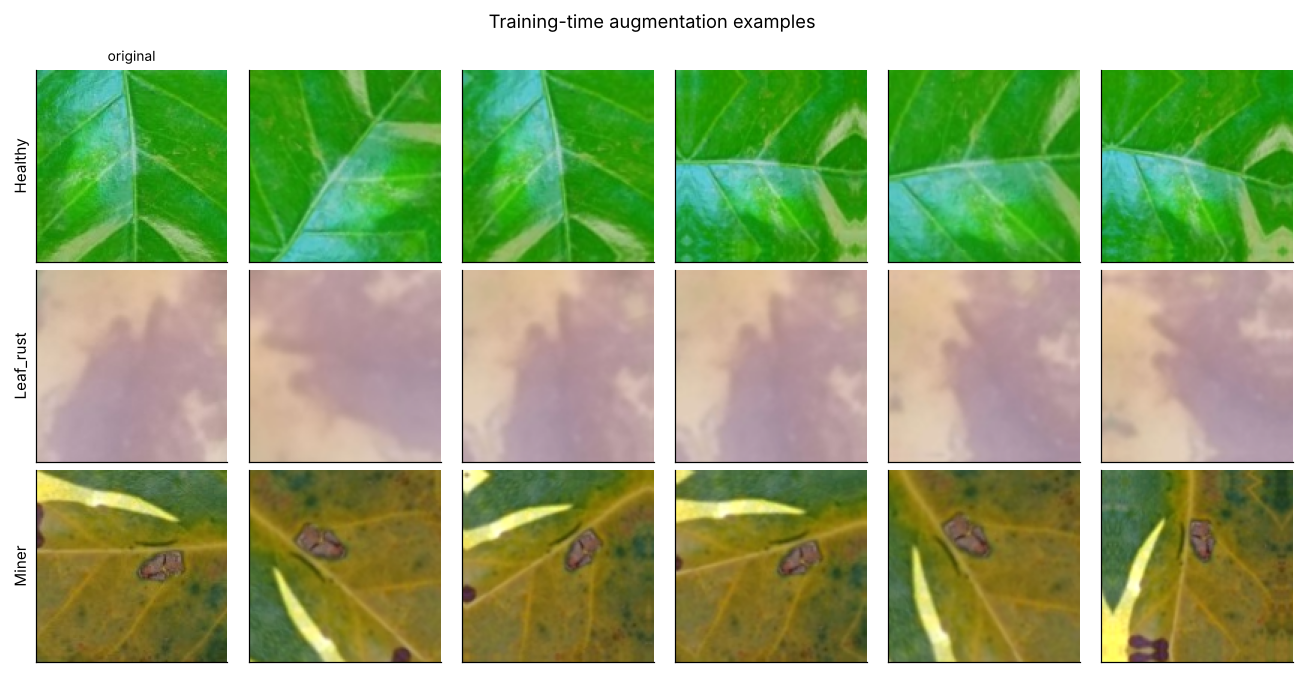

In [10]:
aug = M.augmentation_block()
idx = [int(np.where(y_tr == CLASS_NAMES.index(c))[0][0]) for c in ["Healthy", "Leaf_rust", "Miner"]]
fig, axes = plt.subplots(3, 6, figsize=(12, 6.2))
for r, i in enumerate(idx):
    axes[r, 0].imshow(X_tr[i]); axes[r, 0].set_title("original" if r == 0 else "", fontsize=9)
    for j in range(1, 6):
        axes[r, j].imshow(np.clip(aug(X_tr[i][None].astype("float32"), training=True)[0].numpy(), 0, 255).astype("uint8"))
    axes[r, 0].set_ylabel(CLASS_NAMES[y_tr[i]])
for a in axes.flat: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Training-time augmentation examples"); plt.tight_layout(); plt.show()

## 5. Model creation

### 5.1 Baseline — vanilla CNN from scratch
Three conv blocks, no augmentation, no regularisation, no class weights, fixed 12 epochs, no early stopping.
This is the reference point the optimised model must beat.

In [11]:
tf.random.set_seed(SEED)
baseline = M.compile_model(M.build_baseline_cnn(), lr=1e-3)
t0 = time.time()
h_base = baseline.fit(M.make_dataset(X_tr, y_tr, 32, shuffle=True), validation_data=M.make_dataset(X_val, y_val),
                      epochs=12, verbose=2)
print(f"baseline trained in {time.time()-t0:.0f}s")

Epoch 1/12


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


70/70 - 6s - 85ms/step - accuracy: 0.6351 - loss: 0.9594 - val_accuracy: 0.8124 - val_loss: 0.5877


Epoch 2/12


70/70 - 5s - 66ms/step - accuracy: 0.8185 - loss: 0.4915 - val_accuracy: 0.8433 - val_loss: 0.3874


Epoch 3/12


... (16 outputs left out)

70/70 - 5s - 70ms/step - accuracy: 0.9722 - loss: 0.0905 - val_accuracy: 0.8530 - val_loss: 0.4356


Epoch 12/12


70/70 - 4s - 64ms/step - accuracy: 0.9718 - loss: 0.0934 - val_accuracy: 0.9381 - val_loss: 0.2145


baseline trained in 59s


### 5.2 Optimised model — MobileNetV2 transfer learning

Optimisation techniques used:
* **Pre-trained model**: MobileNetV2 with ImageNet weights as a frozen feature extractor, then fine-tuned
* **Regularisation**: Dropout + L2 weight decay on the dense head, plus data augmentation
* **Optimiser**: Adam, with `ReduceLROnPlateau` learning-rate scheduling
* **Early stopping** on validation loss (restores the best weights)
* **Class weights** for imbalance
* **Hyper-parameter search** over learning rate × dropout (selected on the validation set, never on test)

#### Hyper-parameter search (frozen backbone, 6 epochs each)

In [12]:
hp_results = []
for lr in [1e-3, 3e-4]:
    for dropout in [0.3, 0.5]:
        tf.random.set_seed(SEED)
        m = M.compile_model(M.build_transfer_model(dropout=dropout), lr=lr)
        h = M.train(m, X_tr, y_tr, X_val, y_val, epochs=6, class_weight=CW, patience=3, verbose=0)
        best = int(np.argmin(h.history["val_loss"]))
        hp_results.append({"lr": lr, "dropout": dropout, "val_loss": h.history["val_loss"][best],
                           "val_accuracy": h.history["val_accuracy"][best], "best_epoch": best + 1})
        print(hp_results[-1])
hp_df = pd.DataFrame(hp_results).sort_values("val_loss"); hp_df

Restoring model weights from the end of the best epoch: 5.


{'lr': 0.001, 'dropout': 0.3, 'val_loss': 0.11564142256975174, 'val_accuracy': 0.967117965221405, 'best_epoch': 5}


Restoring model weights from the end of the best epoch: 6.


{'lr': 0.001, 'dropout': 0.5, 'val_loss': 0.09383539855480194, 'val_accuracy': 0.9748549461364746, 'best_epoch': 6}


Restoring model weights from the end of the best epoch: 6.


{'lr': 0.0003, 'dropout': 0.3, 'val_loss': 0.09548785537481308, 'val_accuracy': 0.9767891764640808, 'best_epoch': 6}


Restoring model weights from the end of the best epoch: 6.


{'lr': 0.0003, 'dropout': 0.5, 'val_loss': 0.11292251944541931, 'val_accuracy': 0.9709864854812622, 'best_epoch': 6}


,lr,dropout,val_loss,val_accuracy,best_epoch
1,0.0010,0.5,0.093835,0.974855,6
2,0.0003,0.3,0.095488,0.976789,6
3,0.0003,0.5,0.112923,0.970986,6
0,0.0010,0.3,0.115641,0.967118,5


In [13]:
best_hp = hp_df.iloc[0].to_dict()
print("Selected:", best_hp)

# Phase 1 - train the classification head on top of the frozen ImageNet backbone
tf.random.set_seed(SEED)
model = M.compile_model(M.build_transfer_model(dropout=best_hp["dropout"]), lr=best_hp["lr"])
model.summary(show_trainable=True, line_length=100)
t0 = time.time()
h1 = M.train(model, X_tr, y_tr, X_val, y_val, epochs=20, class_weight=CW, patience=4)
print(f"phase 1: {time.time()-t0:.0f}s")

Selected: {'lr': 0.001, 'dropout': 0.5, 'val_loss': 0.09383539855480194, 'val_accuracy': 0.9748549461364746, 'best_epoch': 6.0}


Model: "coffee_leaf_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                  ┃        Param # ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ image (InputLayer)                    │ (None, 128, 128, 3)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ augmentation (Sequential)             │ (None, 128, 128, 3)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ scale_to_pm1 (Rescaling)              │ (None, 128, 128, 3)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ mobilenetv2_1.00_128 (Functional)     │ (None, 4, 4, 1280)            │      2,257,984 │    N    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ gap (GlobalAveragePooling2D)          │ (None, 1280)                  │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ dropout_1 (Dropout)                   │ (None, 1280)                  │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ dense_128 (Dense)                     │ (None, 128)                   │        163,968 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ dropout_2 (Dropout)                   │ (None, 128)                   │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ predictions (Dense)                   │ (None, 5)                     │            645 │    Y    │
└───────────────────────────────────────┴───────────────────────────────┴────────────────┴─────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (28 outputs left out)

70/70 - 13s - 186ms/step - accuracy: 0.9695 - loss: 0.1368 - val_accuracy: 0.9749 - val_loss: 0.0793 - learning_rate: 3.0000e-04


Epoch 13: early stopping


Restoring model weights from the end of the best epoch: 9.


phase 1: 199s


#### Phase 2 — fine-tune the top 30 layers of MobileNetV2 with a 10× smaller learning rate

In [14]:
M.unfreeze_top(model, n_layers=30)
M.compile_model(model, lr=best_hp["lr"] / 10)
print("trainable weights:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
t0 = time.time()
h2 = M.train(model, X_tr, y_tr, X_val, y_val, epochs=12, class_weight=CW, patience=3)
print(f"phase 2: {time.time()-t0:.0f}s")

trainable weights: 1675333
Epoch 1/12


70/70 - 19s - 275ms/step - accuracy: 0.8875 - loss: 0.3875 - val_accuracy: 0.9342 - val_loss: 0.1857 - learning_rate: 1.0000e-04


Epoch 2/12


70/70 - 20s - 288ms/step - accuracy: 0.9332 - loss: 0.2120 - val_accuracy: 0.9729 - val_loss: 0.1001 - learning_rate: 1.0000e-04


Epoch 3/12


70/70 - 21s - 299ms/step - accuracy: 0.9234 - loss: 0.3207 - val_accuracy: 0.9826 - val_loss: 0.0632 - learning_rate: 1.0000e-04


... (19 outputs left out)

70/70 - 14s - 195ms/step - accuracy: 0.9973 - loss: 0.0314 - val_accuracy: 0.9884 - val_loss: 0.0513 - learning_rate: 9.0000e-06


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.


phase 2: 203s


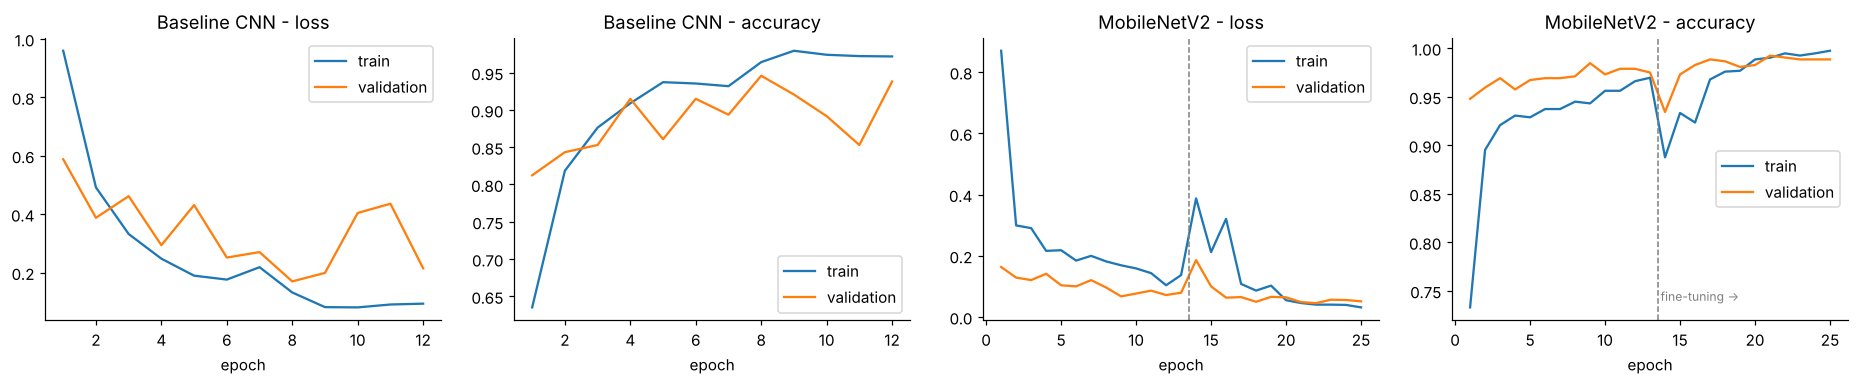

In [15]:
def curves(ax, hist_list, key, title):
    vals, vvals = [], []
    for h in hist_list: vals += h.history[key]; vvals += h.history["val_" + key]
    ax.plot(range(1, len(vals) + 1), vals, label="train"); ax.plot(range(1, len(vvals) + 1), vvals, label="validation")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
curves(ax[0], [h_base], "loss", "Baseline CNN - loss"); curves(ax[1], [h_base], "accuracy", "Baseline CNN - accuracy")
curves(ax[2], [h1, h2], "loss", "MobileNetV2 - loss"); curves(ax[3], [h1, h2], "accuracy", "MobileNetV2 - accuracy")
for a in ax[2:]: a.axvline(len(h1.history["loss"]) + .5, ls="--", c="grey", lw=1)
ax[3].text(len(h1.history["loss"]) + .7, ax[3].get_ylim()[0] + .02, "fine-tuning ->", fontsize=8, color="grey")
plt.tight_layout(); plt.show()

The baseline's training accuracy climbs towards 100 % while validation loss rises: classic **overfitting** on a small dataset.
The transfer-learning model's train and validation curves stay close (augmentation + dropout + L2 do their job), and
fine-tuning adds a final improvement.

## 6. Model testing on the held-out test set

In [16]:
res_base = M.evaluate(baseline, X_te, y_te)
res_opt = M.evaluate(model, X_te, y_te)
res_val = M.evaluate(model, X_val, y_val)
keys = ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr_macro"]
comparison = pd.DataFrame({"Baseline CNN": {k: res_base[k] for k in keys},
                           "MobileNetV2 (optimised)": {k: res_opt[k] for k in keys}}).round(4)
comparison

,Baseline CNN,MobileNetV2 (optimised)
accuracy,0.9433,0.9782
loss,0.2230,0.0849
precision_macro,0.8904,0.9836
recall_macro,0.9515,0.9830
f1_macro,0.9147,0.9833
f1_weighted,0.9436,0.9782
roc_auc_ovr_macro,0.9912,0.9990


In [17]:
from sklearn.metrics import classification_report
proba = M.predict_proba(model, X_te); pred = proba.argmax(1)
print(classification_report(y_te, pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

  Cercospora     1.0000    1.0000    1.0000        68
     Healthy     1.0000    1.0000    1.0000        10
   Leaf_rust     1.0000    1.0000    1.0000       208
       Miner     0.9700    0.9737    0.9719       266
       Phoma     0.9481    0.9412    0.9446       136

    accuracy                         0.9782       688
   macro avg     0.9836    0.9830    0.9833       688
weighted avg     0.9782    0.9782    0.9782       688



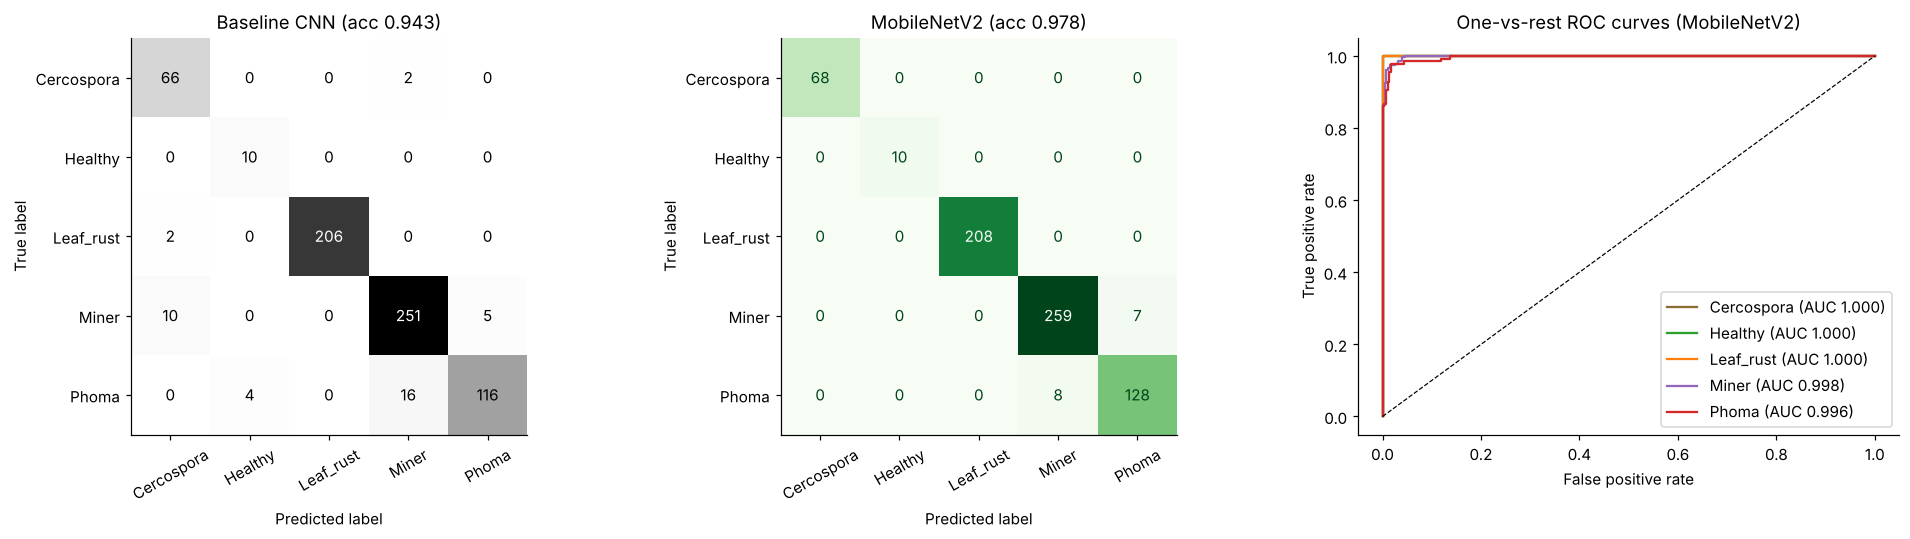

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(np.array(res_base["confusion_matrix"]), display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Greys", colorbar=False, xticks_rotation=30)
ax[0].set_title(f"Baseline CNN (acc {res_base['accuracy']:.3f})")
ConfusionMatrixDisplay(np.array(res_opt["confusion_matrix"]), display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Greens", colorbar=False, xticks_rotation=30)
ax[1].set_title(f"MobileNetV2 (acc {res_opt['accuracy']:.3f})")
from sklearn.metrics import roc_curve, auc
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve((y_te == i).astype(int), proba[:, i])
    ax[2].plot(fpr, tpr, color=COLORS[c], label=f"{c} (AUC {auc(fpr, tpr):.3f})")
ax[2].legend(loc="lower right"); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].plot([0, 1], [0, 1], "k--", lw=.8); ax[2].set_title("One-vs-rest ROC curves (MobileNetV2)")
plt.tight_layout(); plt.show()

### 6.1 Error analysis — the model's mistakes on the test set

15 misclassified out of 688


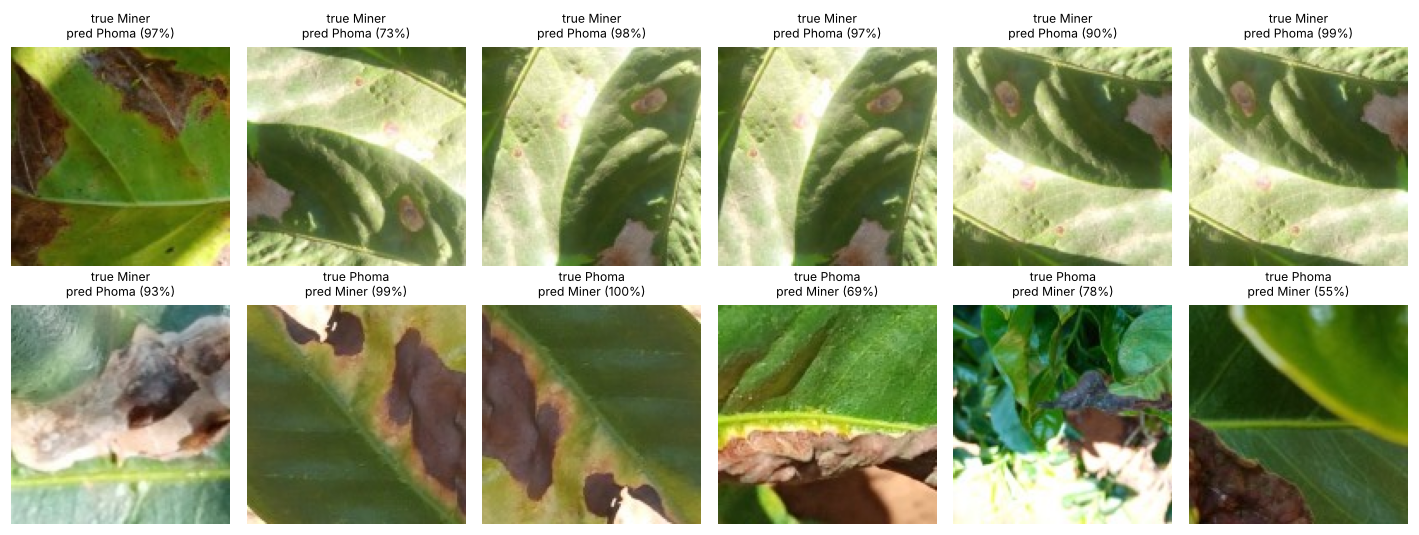

In [19]:
wrong = np.where(pred != y_te)[0]
print(f"{len(wrong)} misclassified out of {len(y_te)}")
n = min(12, len(wrong))
if n:
    fig, axes = plt.subplots(2, 6, figsize=(13, 5))
    for a in axes.flat: a.axis("off")
    for a, i in zip(axes.flat, wrong[:n]):
        a.imshow(X_te[i]); a.set_title(f"true {CLASS_NAMES[y_te[i]]}\npred {CLASS_NAMES[pred[i]]} ({proba[i].max():.0%})", fontsize=8)
    plt.tight_layout(); plt.show()

## 7. Save the model and test the prediction function

The production model is saved as **`models/coffee_leaf_model.h5`** (the baseline is kept as `models/baseline_cnn.h5` for reference).
`models/metrics.json` stores the evaluation results that the web UI displays and that the retraining pipeline compares against.

In [20]:
def hist_dict(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items(): out.setdefault(k, []).extend(float(x) for x in v)
    return out

metrics = {
    "model": "MobileNetV2 transfer learning (ImageNet) + Dropout/L2 head, fine-tuned top 30 layers",
    "version": time.strftime("%Y%m%d-%H%M%S"), "trained_at": time.time(),
    "class_names": CLASS_NAMES, "img_size": IMG_SIZE,
    "hyperparameters": {"lr": best_hp["lr"], "dropout": best_hp["dropout"], "batch_size": 32, "fine_tune_layers": 30},
    "hp_search": hp_results,
    "n_train_images": int(len(X_tr)), "n_val_images": int(len(X_val)), "n_test_images": int(len(X_te)),
    "test": res_opt, "val": res_val, "baseline_test": res_base,
    "history": hist_dict(h1, h2), "phase1_epochs": len(h1.history["loss"]),
}
M.save(model, MODEL_PATH, metrics)
baseline.save(BASELINE_MODEL_PATH)
print("saved", MODEL_PATH, f"({MODEL_PATH.stat().st_size/1e6:.1f} MB)")

saved /home/claude/coffee_leaf_mlops/models/coffee_leaf_model.h5 (23.5 MB)


### 7.1 Export for deployment

The app is deployed on a free cloud instance with 512 MB of RAM, where TensorFlow alone (~600 MB) does not fit.
So the trained model is exported in two parts that together make exactly the same predictions:

| File | What it is |
|---|---|
| `models/feature_extractor.tflite` | Rescaling + the fine-tuned MobileNetV2 + global average pooling, as TensorFlow Lite (image → 1,280 features) |
| `models/classifier_head.npz` | The weights of the trained Dense(128) and Dense(5) layers, run with NumPy |
| `data/embeddings.npz` | The features of all 3,436 images, reused by retraining instead of re-reading every image |

The API (`src/serving.py`, `src/prediction.py`) only needs these files, uses ~100 MB of RAM, and does not import TensorFlow.
The cell below checks the export against the Keras model on the whole test set.

In [23]:
from src.serving import ClassifierHead, FeatureExtractor, metrics_from_proba

print(M.export_for_serving(model, manifest, ROOT))

keras_proba = M.predict_proba(model, X_te)
lite_proba = ClassifierHead.load().predict_proba(FeatureExtractor()(X_te))
print(f"same predicted class on {(keras_proba.argmax(1) == lite_proba.argmax(1)).mean():.1%} of {len(X_te)} test images, "
      f"largest probability difference {np.abs(keras_proba - lite_proba).max():.1e}")
lite_metrics = metrics_from_proba(y_te, lite_proba)
pd.DataFrame({"Keras model (.h5)": {k: res_opt[k] for k in keys},
              "Exported model (TFLite + head)": {k: lite_metrics[k] for k in keys}}).round(4)

{'tflite_mb': 8.9, 'n_embeddings': 3436}


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


same predicted class on 100.0% of 688 test images, largest probability difference 1.6e-05


,Keras model (.h5),Exported model (TFLite + head)
accuracy,0.9782,0.9782
loss,0.0849,0.0849
precision_macro,0.9836,0.9836
recall_macro,0.9830,0.9830
f1_macro,0.9833,0.9833
f1_weighted,0.9782,0.9782
roc_auc_ovr_macro,0.9990,0.9990


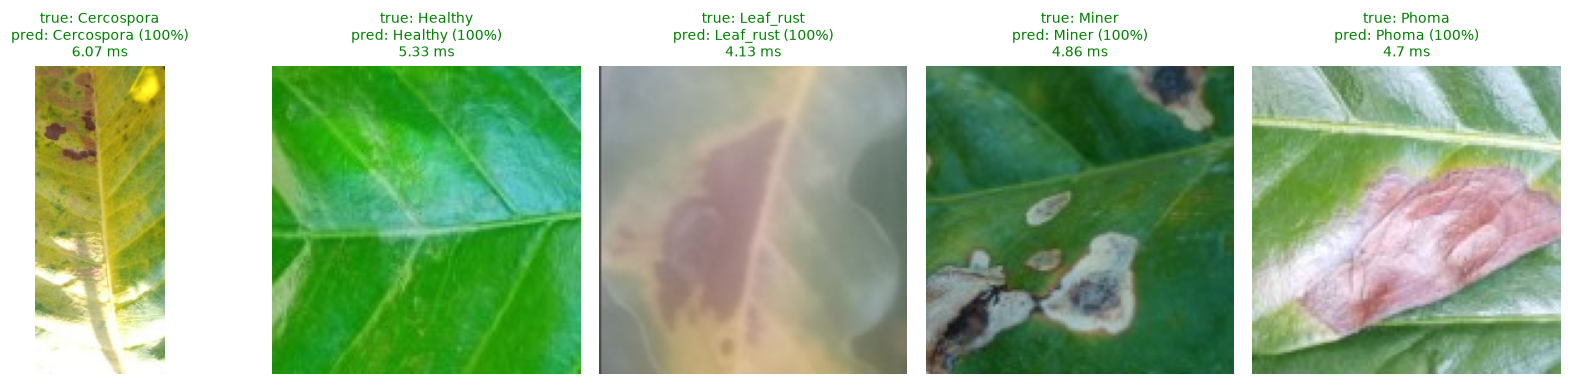

In [24]:
from src.prediction import Predictor
predictor = Predictor()          # the same code the API uses
rng = random.Random(7)
sample = [rng.choice([p for p in te_paths if f"/{c}/" in p]) for c in CLASS_NAMES]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for a, p in zip(axes, sample):
    r = predictor.predict(ROOT / p)
    true = Path(p).parent.name
    a.imshow(P.open_image(ROOT / p)); a.axis("off")
    a.set_title(f"true: {true}\npred: {r['prediction']} ({r['confidence']:.0%})\n{r['latency_ms']} ms",
                fontsize=9, color="green" if true == r["prediction"] else "red")
plt.tight_layout(); plt.show()

## 8. Retraining (how it works in production)

`src/retrain.py` implements the retraining loop that the API/UI exposes:

1. **Upload** — users upload many labelled images (or a zip with one folder per class) via the UI → files saved to
   `data/uploads/<label>/` and registered in the SQLite database `data/mlops.db` with status `pending`.
2. **Trigger** — retraining starts when the user clicks **Retrain** or **automatically** once
   `RETRAIN_THRESHOLD` (default 50) new images are pending.
3. **Preprocess** — every pending image is validated, converted to RGB, resized to 128×128, de-duplicated and copied into `data/train/<label>/`.
4. **Retrain from the custom pre-trained model** — the current production model is the starting point, not a fresh network:
   the new images go through our fine-tuned MobileNetV2 (`feature_extractor.tflite`), and the current classifier head
   (`classifier_head.npz`) is fine-tuned on the stored features of the existing training images plus the new ones
   (Adam, class weights, L2, early stopping on the validation set). Keeping the backbone fixed lets retraining run in
   seconds within 512 MB on the free cloud instance.
5. **Evaluate & promote** — old and new models are compared on the same test set; the new model replaces the old
   one only if neither accuracy nor macro-F1 drops by more than 2 points. The previous model is archived in `models/archive/`, and every run is logged in the
   `training_runs` table and shown in the UI.

Run from the command line: `python -m src.retrain --upload-dir path/to/new_images`.

In [22]:
print(json.dumps({k: metrics["test"][k] for k in keys}, indent=2))

{
  "accuracy": 0.9781976744186046,
  "loss": 0.08489096164703369,
  "precision_macro": 0.9836371202663337,
  "recall_macro": 0.9829721362229102,
  "f1_macro": 0.9833013714752532,
  "f1_weighted": 0.9781779011886719,
  "roc_auc_ovr_macro": 0.9989679420875252
}
